<a href="https://colab.research.google.com/github/razorbladesky/ruta-inundacion-ia/blob/main/simulacion_inundacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np

# ==========================================
# 1. CONSTANTES DE CONFIGURACIÓN
# ==========================================

# Representa un obstáculo infranqueable (pared o zona inaccesible)
BLOQUEADO = -1

# Niveles de inundación en las celdas transitables
SECO = 0
RIESGO_BAJO = 1
RIESGO_MEDIO = 2
RIESGO_ALTO = 3

# Diccionario de costos de entrada a cada tipo de celda transitable
# A mayor nivel de inundación, mayor es el esfuerzo (costo) para cruzar la celda
COSTOS = {
    SECO: 1,          # Tránsito normal
    RIESGO_BAJO: 3,   # Agua a los tobillos
    RIESGO_MEDIO: 6,  # Agua a las rodillas
    RIESGO_ALTO: 10   # Corriente fuerte, requiere mucho cuidado
}

# ==========================================
# 2. CREACIÓN DEL MAPA
# ==========================================

def crear_mapa_principal():
    """
    Crea y devuelve el mapa de la simulación de 10x10.
    Los valores representan el nivel de riesgo de inundación o si está bloqueado.
    """
    mapa_lista = [
        [ 0,  0,  0,  1,  0, -1,  0,  0,  1,  0],
        [ 0,  0,  1,  1,  0, -1,  0,  1,  0,  0],
        [ 0,  1,  1,  1,  1,  3,  1,  1,  1,  0],
        [ 0,  0,  2,  2,  1, -1,  1,  2,  0,  0],
        [ 0,  0,  2,  3,  1, -1,  1,  3,  2,  0],
        [ 0,  1,  2,  3,  2, -1,  2,  2,  1,  0],
        [ 0,  0,  1,  2,  1, -1,  1,  1,  0,  0],
        [ 0,  0,  0,  1,  0, -1,  0,  0,  0,  0],
        [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
        [ 0,  0,  1,  1,  0, -1,  0,  1,  0,  0]
    ]
    return np.array(mapa_lista)

# ==========================================
# 3. COORDENADAS DE INICIO Y DESTINO
# ==========================================
# Formato (fila, columna)
INICIO = (2, 0)
REFUGIO = (2, 9)

# ==========================================
# 4. FUNCIÓN PARA IMPRIMIR EL MAPA
# ==========================================

def imprimir_mapa(mapa, inicio, refugio):
    """
    Imprime una representación visual del mapa en consola.
    - 'I' representa la posición inicial.
    - 'R' representa el refugio seguro.
    - '#' representa las zonas bloqueadas (-1).
    - Los números representan el nivel de inundación (0, 1, 2, 3).
    """
    filas, columnas = mapa.shape

    for f in range(filas):
        fila_texto = []
        for c in range(columnas):
            coordenada_actual = (f, c)
            valor = mapa[f, c]

            # Prioridad de dibujado: Inicio -> Refugio -> Obstáculos/Terreno
            if coordenada_actual == inicio:
                fila_texto.append('I')
            elif coordenada_actual == refugio:
                fila_texto.append('R')
            elif valor == BLOQUEADO:
                fila_texto.append('#')
            else:
                fila_texto.append(str(valor))

        # Unimos los elementos con un espacio para que se vea ordenado y cuadrado
        print(" ".join(fila_texto))

# ==========================================
# 5. EJECUCIÓN Y PRUEBA
# ==========================================

# Inicializamos el mapa
mapa_simulacion = crear_mapa_principal()

# Mostramos las dimensiones del mapa
print(f"Dimensiones del mapa generado: {mapa_simulacion.shape} (10 filas x 10 columnas)\n")

# Imprimimos la representación visual del mapa
print("Visualización del mapa (I = Inicio, R = Refugio, # = Bloqueado):")
imprimir_mapa(mapa_simulacion, INICIO, REFUGIO)

Dimensiones del mapa generado: (10, 10) (10 filas x 10 columnas)

Visualización del mapa (I = Inicio, R = Refugio, # = Bloqueado):
0 0 0 1 0 # 0 0 1 0
0 0 1 1 0 # 0 1 0 0
I 1 1 1 1 3 1 1 1 R
0 0 2 2 1 # 1 2 0 0
0 0 2 3 1 # 1 3 2 0
0 1 2 3 2 # 2 2 1 0
0 0 1 2 1 # 1 1 0 0
0 0 0 1 0 # 0 0 0 0
0 0 0 0 0 0 0 0 0 0
0 0 1 1 0 # 0 1 0 0


In [ ]:
def obtener_vecinos(mapa, celda):
    """
    Devuelve los vecinos válidos de una celda en el siguiente orden fijo:
    arriba, derecha, abajo, izquierda.
    Un vecino es válido si está dentro de los límites y no está BLOQUEADO.
    """
    fila, col = celda
    filas_max, columnas_max = mapa.shape
    vecinos_validos = []

    # Movimientos posibles en el orden requerido:
    # Arriba (-1, 0), Derecha (0, +1), Abajo (+1, 0), Izquierda (0, -1)
    movimientos = [
        (fila - 1, col),  # Arriba
        (fila, col + 1),  # Derecha
        (fila + 1, col),  # Abajo
        (fila, col - 1)   # Izquierda
    ]

    for f, c in movimientos:
        # 1. Verificar límites de la matriz
        if 0 <= f < filas_max and 0 <= c < columnas_max:
            # 2. Verificar que no esté bloqueado
            if mapa[f, c] != BLOQUEADO:
                vecinos_validos.append((f, c))

    return vecinos_validos


def costo_de_ruta(mapa, ruta):
    """
    Calcula el costo total de transitar por una ruta.
    La primera celda (inicio) no suma costo.
    Retorna None si la ruta es inválida, vacía o toca zonas bloqueadas.
    """
    # Validación de ruta nula o vacía
    if ruta is None or len(ruta) < 1:
        return None

    costo_total = 0

    # Recorremos cada celda de la ruta indicando su posición (índice)
    for i, celda in enumerate(ruta):
        f, c = celda
        valor_celda = mapa[f, c]

        # Si la celda está bloqueada, la ruta es inválida
        if valor_celda == BLOQUEADO:
            return None

        # El inicio (índice 0) no suma costo
        if i > 0:
            costo_total += COSTOS[valor_celda]

    return costo_total

# ==========================================
# PRUEBAS UNITARIAS (ASSERTS)
# ==========================================

# Usamos el mapa cargado en la celda anterior
mapa = mapa_simulacion

# Prueba 1: Vecinos en (2, 0) -> Arriba, Derecha, Abajo (Izquierda está fuera de límites)
assert obtener_vecinos(mapa, (2, 0)) == [(1, 0), (2, 1), (3, 0)], "Error en vecinos de (2, 0)"

# Prueba 2: Vecinos en (0, 0) -> Derecha, Abajo (Arriba e Izquierda fuera de límites)
assert obtener_vecinos(mapa, (0, 0)) == [(0, 1), (1, 0)], "Error en vecinos de (0, 0)"

# Prueba 3: Vecinos en (1, 4) -> Arriba, Abajo, Izquierda (Derecha (1, 5) es bloqueado '#')
assert obtener_vecinos(mapa, (1, 4)) == [(0, 4), (2, 4), (1, 3)], "Error en vecinos de (1, 4)"

# Prueba 4: Costo de la ruta directa horizontal de fila 2: desde (2, 0) hasta (2, 9)
ruta_fila_2 = [(2, i) for i in range(10)]
assert costo_de_ruta(mapa, ruta_fila_2) == 32, f"Error: se esperaba costo 32, pero se obtuvo {costo_de_ruta(mapa, ruta_fila_2)}"

# Prueba 5: Costo de ruta con una sola celda (solo inicio)
assert costo_de_ruta(mapa, [(2, 0)]) == 0, "Error: la ruta de un solo paso debe costar 0"

# Prueba 6: Ruta que pasa por un obstáculo bloqueado (0, 5)
ruta_con_bloqueo = [(0, 4), (0, 5), (0, 6)]
assert costo_de_ruta(mapa, ruta_con_bloqueo) is None, "Error: ruta con bloqueos debe retornar None"

print("Parte 2: todas las pruebas pasaron")

Parte 2: todas las pruebas pasaron


In [ ]:
from collections import deque

def bfs(mapa, inicio, refugio):
    """
    Implementa búsqueda en anchura (BFS) para encontrar la ruta con menos pasos.
    Devuelve una tupla (ruta, costo, nodos_expandidos).
    """
    # Caso 1: Si la celda de inicio está bloqueada, no hay búsqueda
    if mapa[inicio] == BLOQUEADO:
        return (None, None, 0)

    # Caso 2: Si el inicio ya es el refugio
    if inicio == refugio:
        return ([inicio], 0, 1)

    # Inicialización de la cola de exploración y el conjunto de visitados
    # Guardamos tuplas con (celda_actual)
    cola = deque([inicio])

    # Marcamos como visitada al meterla en la cola
    visitados = {inicio}

    # Diccionario para rastrear de dónde venimos y reconstruir el camino
    padres = {inicio: None}

    nodos_expandidos = 0

    # Bucle principal de BFS
    while cola:
        # Sacar el primer nodo de la cola (FIFO) y contabilizar su expansión
        actual = cola.popleft()
        nodos_expandidos += 1

        # Si llegamos al refugio al SACARLO, terminamos
        if actual == refugio:
            break

        # Obtener los vecinos válidos usando la función definida anteriormente
        vecinos = obtener_vecinos(mapa, actual)

        for vecino in vecinos:
            if vecino not in visitados:
                # Marcar al METER en la cola
                visitados.add(vecino)
                padres[vecino] = actual
                cola.append(vecino)

    # Si salimos del bucle y el refugio nunca se visitó, no es alcanzable
    if refugio not in visitados:
        return (None, None, nodos_expandidos)

    # Reconstrucción del camino desde el refugio hacia el inicio
    ruta = []
    actual = refugio
    while actual is not None:
        ruta.append(actual)
        actual = padres[actual]

    # Invertimos la ruta para tenerla de inicio a fin
    ruta.reverse()

    # Calcular costo de entrada usando la función costo_de_ruta creada antes
    costo = costo_de_ruta(mapa, ruta)

    return (ruta, costo, nodos_expandidos)

# ==========================================
# PRUEBAS UNITARIAS (ASSERTS)
# ==========================================

# 1. Prueba en mapa principal
ruta_bfs, costo_bfs, expandidos_bfs = bfs(mapa_simulacion, INICIO, REFUGIO)
assert ruta_bfs == [(2, i) for i in range(10)], "Error: La ruta obtenida no es la directa por la fila 2"
assert costo_bfs == 32, f"Error: El costo debería ser 32, se obtuvo {costo_bfs}"
assert len(ruta_bfs) - 1 == 9, "Error: La cantidad de pasos (aristas) debe ser 9"

# 2. Prueba con inicio == refugio
r_mismo, c_mismo, e_mismo = bfs(mapa_simulacion, INICIO, INICIO)
assert r_mismo == [INICIO] and c_mismo == 0 and e_mismo == 1, "Error en caso inicio == refugio"

# 3. Prueba aislando el refugio (bloqueando sus entradas: (1,9), (3,9), (2,8))
mapa_aislado = mapa_simulacion.copy()
mapa_aislado[1, 9] = BLOQUEADO
mapa_aislado[3, 9] = BLOQUEADO
mapa_aislado[2, 8] = BLOQUEADO
r_aislado, c_aislado, e_aislado = bfs(mapa_aislado, INICIO, REFUGIO)
assert r_aislado is None, "Error: el refugio no debería ser alcanzable"
assert c_aislado is None, "Error: el costo debe ser None para rutas imposibles"
assert e_aislado > 0, "Error: se deben haber expandido nodos antes de darse por vencido"

# 4. Prueba con inicio bloqueado
mapa_bloq_inicio = mapa_simulacion.copy()
mapa_bloq_inicio[INICIO] = BLOQUEADO
r_bloq, c_bloq, e_bloq = bfs(mapa_bloq_inicio, INICIO, REFUGIO)
assert r_bloq is None and c_bloq is None and e_bloq == 0, "Error: inicio bloqueado debe devolver (None, None, 0)"

print("Parte 3: todas las pruebas pasaron\n")

# ==========================================
# EJECUCIÓN Y VISUALIZACIÓN DE RESULTADOS
# ==========================================

print("=== RESULTADO DE LA BÚSQUEDA EN ANCHURA (BFS) ===")
print(f"Ruta encontrada: {ruta_bfs}")
print(f"Costo total de la ruta: {costo_bfs} unidades de esfuerzo")
print(f"Número de pasos (movimientos): {len(ruta_bfs) - 1}")
print(f"Total de nodos expandidos: {expandidos_bfs}")

Parte 3: todas las pruebas pasaron

=== RESULTADO DE LA BÚSQUEDA EN ANCHURA (BFS) ===
Ruta encontrada: [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9)]
Costo total de la ruta: 32 unidades de esfuerzo
Número de pasos (movimientos): 9
Total de nodos expandidos: 57


In [ ]:
def dfs(mapa, inicio, refugio):
    """
    Implementa búsqueda en profundidad (DFS) iterativa con una pila.
    Mete los vecinos a la pila en orden inverso para priorizar la exploración
    en el orden original de obtener_vecinos (arriba, derecha, abajo, izquierda).
    Devuelve una tupla (ruta, costo, nodos_expandidos).
    """
    # Caso 1: Si la celda de inicio está bloqueada, no hay búsqueda
    if mapa[inicio] == BLOQUEADO:
        return (None, None, 0)

    # Caso 2: Si el inicio ya es el refugio
    if inicio == refugio:
        return ([inicio], 0, 1)

    # Pila de exploración. Cada elemento es una tupla: (celda, padre)
    pila = [(inicio, None)]

    # Conjunto de nodos que ya han sido expandidos (visitados)
    visitados = set()

    # Diccionario para reconstruir el camino al final
    padres = {}

    nodos_expandidos = 0
    encontrado = False

    # Bucle principal de DFS iterativo
    while pila:
        # Sacamos el último elemento de la pila (LIFO)
        actual, padre = pila.pop()

        # Si la celda ya fue visitada/expandida, la saltamos sin penalizar el contador
        if actual in visitados:
            continue

        # Al SACAR la celda, la marcamos como visitada
        visitados.add(actual)
        padres[actual] = padre
        nodos_expandidos += 1

        # Detenerse si sacamos el refugio de la pila
        if actual == refugio:
            encontrado = True
            break

        # Obtener vecinos con obtener_vecinos(mapa, celda)
        vecinos = obtener_vecinos(mapa, actual)

        # Para explorar en el orden original (arriba, derecha, abajo, izquierda):
        # Debemos meterlos a la pila en orden inverso (izquierda, abajo, derecha, arriba)
        for vecino in reversed(vecinos):
            if vecino not in visitados:
                pila.append((vecino, actual))

    # Si terminamos el bucle y el refugio nunca fue alcanzado y desapilado
    if not encontrado:
        return (None, None, nodos_expandidos)

    # Reconstrucción de la ruta hacia atrás
    ruta = []
    actual = refugio
    while actual is not None:
        ruta.append(actual)
        actual = padres[actual]

    # Invertimos la ruta para ir de inicio a fin
    ruta.reverse()

    # Calcular el costo de la ruta usando costo_de_ruta
    costo = costo_de_ruta(mapa, ruta)

    return (ruta, costo, nodos_expandidos)

# ==========================================
# PRUEBAS UNITARIAS (ASSERTS)
# ==========================================

# 1. Prueba básica de DFS sobre el mapa principal
ruta_dfs, costo_dfs, expandidos_dfs = dfs(mapa_simulacion, INICIO, REFUGIO)

assert ruta_dfs is not None, "Error: DFS debería encontrar una ruta al refugio"
assert ruta_dfs[0] == INICIO, "Error: La ruta debe comenzar en el INICIO"
assert ruta_dfs[-1] == REFUGIO, "Error: La ruta debe terminar en el REFUGIO"

# Verificar consecutividad, ausencia de duplicados y no bloqueados en la ruta
for idx in range(len(ruta_dfs)):
    celda_act = ruta_dfs[idx]
    assert mapa_simulacion[celda_act] != BLOQUEADO, f"Error: La celda {celda_act} está bloqueada y no debe estar en la ruta"
    if idx > 0:
        celda_prev = ruta_dfs[idx - 1]
        dist_manhattan = abs(celda_act[0] - celda_prev[0]) + abs(celda_act[1] - celda_prev[1])
        assert dist_manhattan == 1, f"Error: Celdas no adyacentes {celda_prev} y {celda_act}"
assert len(ruta_dfs) == len(set(ruta_dfs)), "Error: La ruta no debe contener celdas duplicadas"

# 2. El costo que devuelve dfs debe ser igual a costo_de_ruta(mapa, ruta)
assert costo_dfs == costo_de_ruta(mapa_simulacion, ruta_dfs), "Error: Inconsistencia en el cálculo del costo"

# 3. La ruta de DFS debe tener al menos tantas celdas como la de BFS
assert len(ruta_dfs) >= len(ruta_bfs), "Error: La ruta de DFS no puede ser más corta en pasos que la de BFS (BFS es óptimo en pasos)"

# 4. Caso de inicio == refugio
r_mismo, c_mismo, e_mismo = dfs(mapa_simulacion, INICIO, INICIO)
assert r_mismo == [INICIO] and c_mismo == 0 and e_mismo == 1, "Error en caso inicio == refugio"

# 5. Aislamos el refugio (bloqueando sus entradas)
mapa_aislado = mapa_simulacion.copy()
mapa_aislado[1, 9] = BLOQUEADO
mapa_aislado[3, 9] = BLOQUEADO
mapa_aislado[2, 8] = BLOQUEADO
r_aislado, c_aislado, e_aislado = dfs(mapa_aislado, INICIO, REFUGIO)
assert r_aislado is None and c_aislado is None, "Error: El refugio no debería ser alcanzable"
assert e_aislado > 0, "Error: Debieron expandirse nodos durante la búsqueda sin éxito"

# 6. Inicio bloqueado
mapa_bloq_inicio = mapa_simulacion.copy()
mapa_bloq_inicio[INICIO] = BLOQUEADO
r_bloq, c_bloq, e_bloq = dfs(mapa_bloq_inicio, INICIO, REFUGIO)
assert r_bloq is None and c_bloq is None and e_bloq == 0, "Error: Inicio bloqueado debe devolver (None, None, 0)"

print("Parte 4: todas las pruebas pasaron\n")

# ==========================================
# EJECUCIÓN Y COMPARATIVA DE RESULTADOS
# ==========================================

print(f"{'-'*38} COMPARATIVA DE BÚSQUEDAS {'-'*38}")
print(f"{'Métrica':<25} | {'BFS (Búsqueda en Anchura)':<30} | {'DFS (Búsqueda en Profundidad)':<30}")
print(f"{'-'*95}")
print(f"{'Costo Total':<25} | {costo_bfs:<30} | {costo_dfs:<30}")
print(f"{'Número de Pasos (aristas)':<25} | {len(ruta_bfs)-1:<30} | {len(ruta_dfs)-1:<30}")
print(f"{'Total Nodos Expandidos':<25} | {expandidos_bfs:<30} | {expandidos_dfs:<30}")
print(f"{'-'*95}")
print(f"\nRuta BFS: {ruta_bfs}")
print(f"\nRuta DFS: {ruta_dfs}")

Parte 4: todas las pruebas pasaron

-------------------------------------- COMPARATIVA DE BÚSQUEDAS --------------------------------------
Métrica                   | BFS (Búsqueda en Anchura)      | DFS (Búsqueda en Profundidad) 
-----------------------------------------------------------------------------------------------
Costo Total               | 32                             | 34                            
Número de Pasos (aristas) | 9                              | 17                            
Total Nodos Expandidos    | 57                             | 18                            
-----------------------------------------------------------------------------------------------

Ruta BFS: [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9)]

Ruta DFS: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (2, 5), (2, 6), (1, 6), (0, 6), (0, 7), (0, 8), (0, 9), (1, 9), (2, 9)]


In [ ]:
import heapq
import itertools

def ucs(mapa, inicio, refugio):
    """
    Implementa la búsqueda de costo uniforme (UCS) usando una cola de prioridad (heapq).
    Devuelve una tupla (ruta, costo, nodos_expandidos).
    """
    # Caso 1: Si la celda de inicio está bloqueada, no hay búsqueda
    if mapa[inicio] == BLOQUEADO:
        return (None, None, 0)

    # Caso 2: Si el inicio ya es el refugio
    if inicio == refugio:
        return ([inicio], 0, 1)

    # Generador de números para evitar que heapq intente comparar tuplas de celdas directamente
    contador_desempate = itertools.count()

    # Cola de prioridad: almacena tuplas de (costo_acumulado, desempate, celda_actual)
    cola_prioridad = []
    heapq.heappush(cola_prioridad, (0, next(contador_desempate), inicio))

    # Registro del menor costo conocido para llegar a cada celda
    mejor_costo = {inicio: 0}

    # Registro de padres para reconstruir la ruta
    padres = {inicio: None}

    # Conjunto de celdas expandidas (sacadas formalmente de la cola)
    expandidos = set()
    nodos_expandidos = 0
    encontrado = False
    costo_acumulado_refugio = None

    while cola_prioridad:
        # Sacamos el nodo con el menor costo acumulado
        costo_acumulado, _, actual = heapq.heappop(cola_prioridad)

        # Si la celda ya fue expandida previamente, la ignoramos
        if actual in expandidos:
            continue

        # Al extraerla formalmente de la cola, la marcamos como expandida
        expandidos.add(actual)
        nodos_expandidos += 1

        # Si llegamos al refugio al sacarlo de la cola, nos detenemos
        if actual == refugio:
            encontrado = True
            costo_acumulado_refugio = costo_acumulado
            break

        # Obtener vecinos válidos usando la función predefinida
        vecinos = obtener_vecinos(mapa, actual)

        for vecino in vecinos:
            # El costo de entrar a este vecino es el costo acumulado actual más el costo del terreno vecino
            nuevo_costo = costo_acumulado + COSTOS[mapa[vecino]]

            # Si no hemos visitado al vecino, o si encontramos un camino más barato hacia él
            if vecino not in mejor_costo or nuevo_costo < mejor_costo[vecino]:
                mejor_costo[vecino] = nuevo_costo
                padres[vecino] = actual
                # Lo añadimos a la cola de prioridad
                heapq.heappush(cola_prioridad, (nuevo_costo, next(contador_desempate), vecino))

    # Si no se logró alcanzar el refugio
    if not encontrado:
        return (None, None, nodos_expandidos)

    # Reconstrucción de la ruta óptima en base al costo acumulado
    ruta = []
    actual = refugio
    while actual is not None:
        ruta.append(actual)
        actual = padres[actual]
    ruta.reverse()

    # Obtener el costo real usando costo_de_ruta
    costo_real = costo_de_ruta(mapa, ruta)

    # Assert interno: El costo real debe coincidir exactamente con el costo con el que salió de la cola
    assert costo_real == costo_acumulado_refugio, f"Discrepancia de costos: real={costo_real}, acumulado={costo_acumulado_refugio}"

    return (ruta, costo_real, nodos_expandidos)

# ==========================================
# PRUEBAS UNITARIAS (ASSERTS)
# ==========================================

# Mapa para pruebas
mapa = mapa_simulacion

# Obtención de resultados para pruebas y comparativa final
ruta_ucs, costo_ucs, expandidos_ucs = ucs(mapa, INICIO, REFUGIO)

# 1. Validación de ruta correcta (existencia, adyacencia, no bloqueados, no repetidos)
assert ruta_ucs is not None, "Error: UCS debería encontrar una ruta al refugio"
assert ruta_ucs[0] == INICIO, "Error: La ruta debe comenzar en el INICIO"
assert ruta_ucs[-1] == REFUGIO, "Error: La ruta debe terminar en el REFUGIO"
for idx in range(len(ruta_ucs)):
    celda_act = ruta_ucs[idx]
    assert mapa[celda_act] != BLOQUEADO, f"Error: La celda {celda_act} está bloqueada"
    if idx > 0:
        celda_prev = ruta_ucs[idx - 1]
        dist_manhattan = abs(celda_act[0] - celda_prev[0]) + abs(celda_act[1] - celda_prev[1])
        assert dist_manhattan == 1, f"Error: Celdas no adyacentes {celda_prev} y {celda_act}"
assert len(ruta_ucs) == len(set(ruta_ucs)), "Error: La ruta de UCS tiene celdas repetidas"

# 2. El costo de UCS en el mapa principal debe ser exactamente 21 con 21 pasos (22 celdas)
assert costo_ucs == 21, f"Error: El costo esperado es 21, se obtuvo {costo_ucs}"
assert len(ruta_ucs) - 1 == 21, f"Error: Se esperaban 21 pasos (22 celdas), se obtuvieron {len(ruta_ucs) - 1}"

# 3. UCS debe optimizar el costo frente a BFS y DFS (siendo en el mapa principal estrictamente menor que BFS)
assert costo_ucs <= costo_bfs, f"Error: El costo de UCS ({costo_ucs}) debería ser <= al de BFS ({costo_bfs})"
assert costo_ucs <= costo_dfs, f"Error: El costo de UCS ({costo_ucs}) debería ser <= al de DFS ({costo_dfs})"
assert costo_ucs < costo_bfs, f"Error: El costo de UCS ({costo_ucs}) debería ser estrictamente menor que el de BFS ({costo_bfs}) en este mapa"

# 4. Caso de inicio == refugio
r_mismo, c_mismo, e_mismo = ucs(mapa, INICIO, INICIO)
assert r_mismo == [INICIO] and c_mismo == 0 and e_mismo == 1, "Error en caso de inicio == refugio"

# 5. Aislamos el refugio bloqueando sus celdas adyacentes
mapa_aislado = mapa.copy()
mapa_aislado[1, 9] = BLOQUEADO
mapa_aislado[3, 9] = BLOQUEADO
mapa_aislado[2, 8] = BLOQUEADO
r_aislado, c_aislado, e_aislado = ucs(mapa_aislado, INICIO, REFUGIO)
assert r_aislado is None and c_aislado is None, "Error: El refugio no debería ser alcanzable"
assert e_aislado > 0, "Error: Debieron expandirse celdas antes de determinar que no hay ruta"

# 6. Inicio bloqueado
mapa_bloq_inicio = mapa.copy()
mapa_bloq_inicio[INICIO] = BLOQUEADO
r_bloq, c_bloq, e_bloq = ucs(mapa_bloq_inicio, INICIO, REFUGIO)
assert r_bloq is None and c_bloq is None and e_bloq == 0, "Error: Inicio bloqueado debe devolver (None, None, 0)"

print("Parte 5: todas las pruebas pasaron\n")

# ==========================================
# COMPARATIVA FINAL DE ALGORITMOS
# ==========================================

# Ejecutamos las búsquedas nuevamente para asegurar consistencia
ruta_bfs, costo_bfs, expandidos_bfs = bfs(mapa, INICIO, REFUGIO)
ruta_dfs, costo_dfs, expandidos_dfs = dfs(mapa, INICIO, REFUGIO)

print(f"{'-'*40} COMPARATIVA GENERAL DE ALGORITMOS {'-'*41}")
print(f"{'Métrica':<25} | {'BFS (Anchura)':<25} | {'DFS (Profundidad)':<25} | {'UCS (Costo Uniforme)':<25}")
print(f"{'-'*114}")
print(f"{'Costo total de ruta':<25} | {costo_bfs:<25} | {costo_dfs:<25} | {costo_ucs:<25}")
print(f"{'Número de pasos':<25} | {len(ruta_bfs)-1:<25} | {len(ruta_dfs)-1:<25} | {len(ruta_ucs)-1:<25}")
print(f"{'Nodos expandidos':<25} | {expandidos_bfs:<25} | {expandidos_dfs:<25} | {expandidos_ucs:<25}")
print(f"{'-'*114}")
print(f"\nRuta BFS: {ruta_bfs}")
print(f"\nRuta DFS: {ruta_dfs}")
print(f"\nRuta UCS: {ruta_ucs}")

Parte 5: todas las pruebas pasaron

---------------------------------------- COMPARATIVA GENERAL DE ALGORITMOS -----------------------------------------
Métrica                   | BFS (Anchura)             | DFS (Profundidad)         | UCS (Costo Uniforme)     
------------------------------------------------------------------------------------------------------------------
Costo total de ruta       | 32                        | 34                        | 21                       
Número de pasos           | 9                         | 17                        | 21                       
Nodos expandidos          | 57                        | 18                        | 71                       
------------------------------------------------------------------------------------------------------------------

Ruta BFS: [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9)]

Ruta DFS: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (

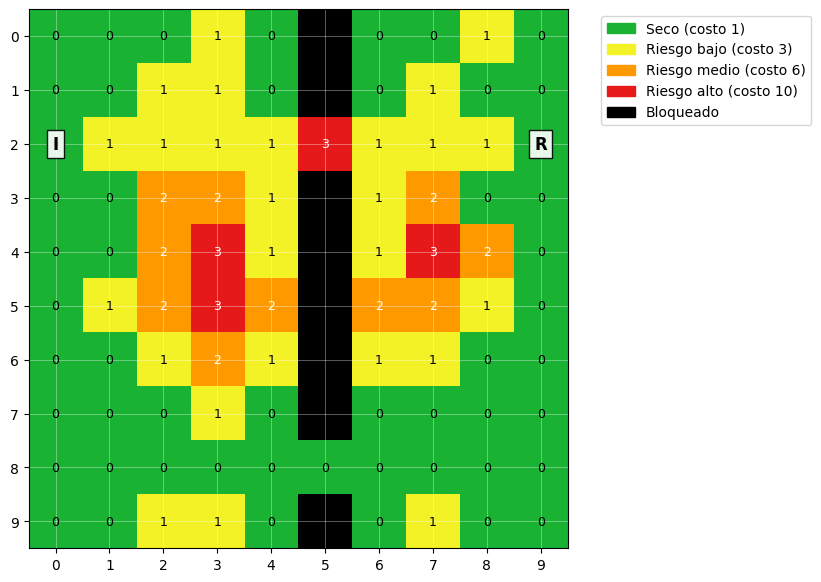

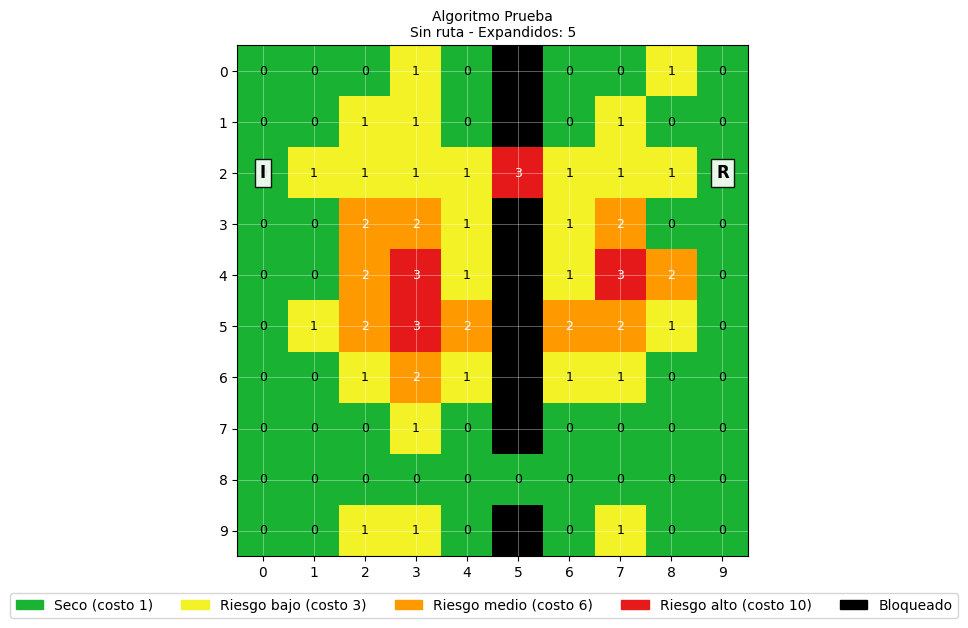

Parte 6: las funciones de visualización no fallan

=== COMPARATIVA VISUAL DE RUTAS ENCONTRADAS ===


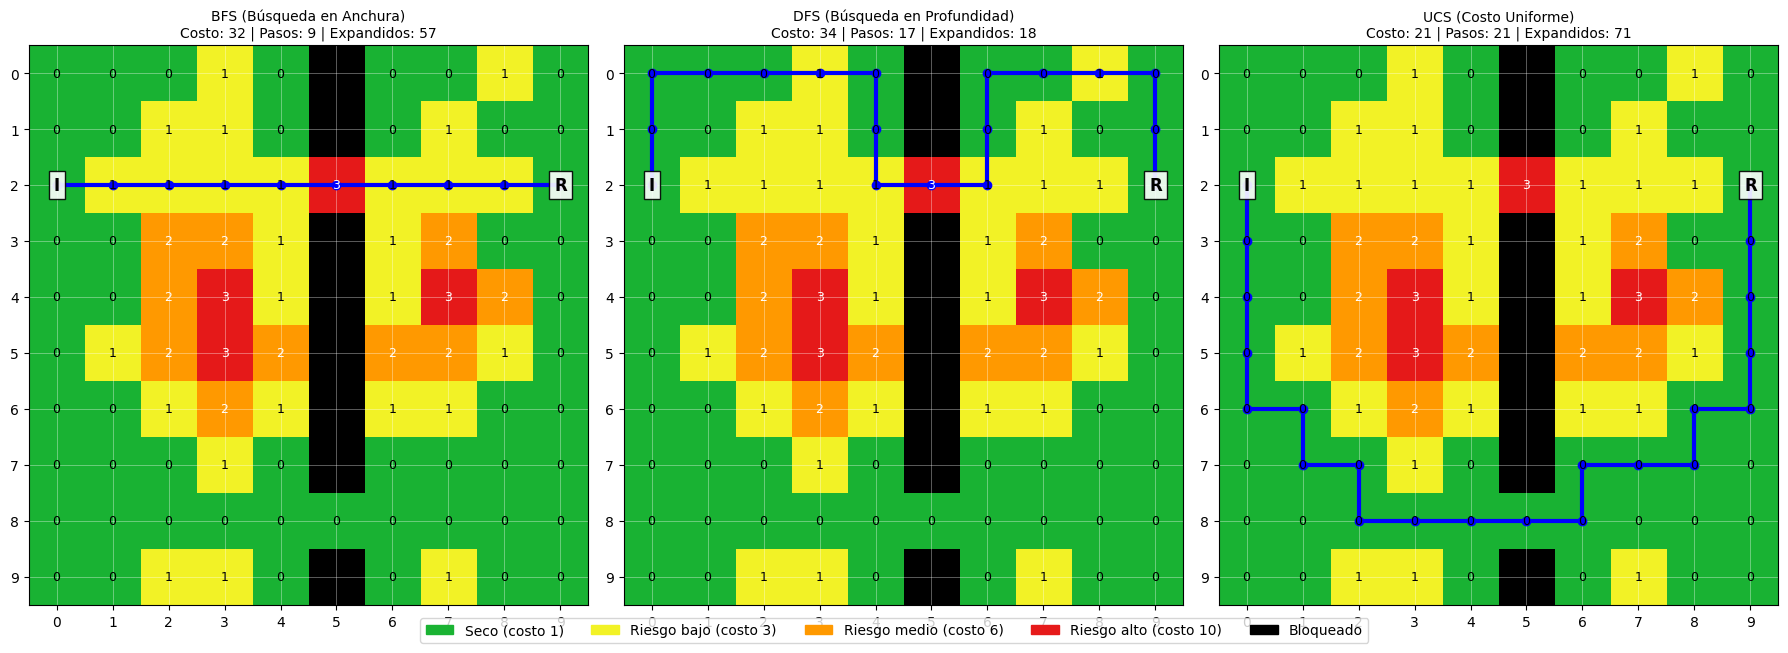

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ==========================================
# 1. FUNCIÓN PARA DIBUJAR EL TERRENO
# ==========================================

def dibujar_terreno(mapa, inicio, refugio, ruta=None, titulo="", ax=None):
    """
    Dibuja el mapa de inundación con colores específicos para cada celda,
    muestra los valores de riesgo, las marcas de inicio/refugio y dibuja la ruta si existe.
    """
    # Definimos la paleta de colores requerida
    # BLOQUEADO (-1) = negro, 0 = verde, 1 = amarillo, 2 = naranja, 3 = rojo
    colores_rgb = {
        -1: [0.0, 0.0, 0.0],     # Negro
         0: [0.1, 0.7, 0.2],     # Verde
         1: [0.95, 0.95, 0.15],  # Amarillo
         2: [1.0, 0.6, 0.0],     # Naranja
         3: [0.9, 0.1, 0.1]      # Rojo
    }

    filas, columnas = mapa.shape

    # Creamos una matriz RGB vacía (filas x columnas x 3 canales)
    matriz_colores = np.zeros((filas, columnas, 3))
    for f in range(filas):
        for c in range(columnas):
            valor = mapa[f, c]
            matriz_colores[f, c] = colores_rgb[valor]

    # Si no se provee un ax, creamos una figura propia
    mi_propio_ax = False
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 7))
        mi_propio_ax = True

    # Mostramos la matriz como imagen.
    # El origen 'upper' garantiza que la fila 0 quede en la parte superior.
    ax.imshow(matriz_colores, origin='upper')

    # Escribimos el nivel de riesgo en las celdas no bloqueadas
    for f in range(filas):
        for c in range(columnas):
            valor = mapa[f, c]
            if valor != BLOQUEADO:
                # Elegimos color del texto para garantizar legibilidad
                color_texto = 'black' if valor in [1, 0] else 'white'
                ax.text(c, f, str(valor), color=color_texto, ha='center', va='center', fontsize=9)

    # Dibujamos las marcas de Inicio (I) y Refugio (R) con recuadro blanco
    propiedades_caja = dict(boxstyle="square,pad=0.3", fc="white", ec="black", lw=1, alpha=0.9)

    # Inicio
    ax.text(inicio[1], inicio[0], "I", color="black", weight="bold",
            ha='center', va='center', fontsize=12, bbox=propiedades_caja)

    # Refugio
    ax.text(refugio[1], refugio[0], "R", color="black", weight="bold",
            ha='center', va='center', fontsize=12, bbox=propiedades_caja)

    # Si hay una ruta válida provista, la dibujamos encima
    if ruta is not None and len(ruta) > 0:
        # Extraemos las coordenadas X (columnas) e Y (filas) de la ruta
        ruta_x = [celda[1] for celda in ruta]
        ruta_y = [celda[0] for celda in ruta]
        ax.plot(ruta_x, ruta_y, color='blue', linewidth=3, marker='o', markersize=6, label="Ruta")

    # Configuración de los ejes para una visualización más limpia
    ax.set_xticks(np.arange(columnas))
    ax.set_yticks(np.arange(filas))
    ax.set_xticklabels(np.arange(columnas))
    ax.set_yticklabels(np.arange(filas))
    ax.grid(color='white', linestyle='-', linewidth=0.5, alpha=0.5)
    ax.set_title(titulo, fontsize=10)

    # Si creamos nuestro propio ax, añadimos la leyenda y mostramos el gráfico
    if mi_propio_ax:
        parches = [
            mpatches.Patch(color=colores_rgb[0], label=f"Seco (costo {COSTOS[0]})"),
            mpatches.Patch(color=colores_rgb[1], label=f"Riesgo bajo (costo {COSTOS[1]})"),
            mpatches.Patch(color=colores_rgb[2], label=f"Riesgo medio (costo {COSTOS[2]})"),
            mpatches.Patch(color=colores_rgb[3], label=f"Riesgo alto (costo {COSTOS[3]})"),
            mpatches.Patch(color=colores_rgb[-1], label="Bloqueado")
        ]
        ax.legend(handles=parches, bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.show()

# ==========================================
# 2. FUNCIÓN PARA COMPARAR VISUALMENTE
# ==========================================

def comparar_visual(mapa, inicio, refugio, resultados):
    """
    Genera una fila de subplots para comparar visualmente las rutas de diferentes algoritmos.
    """
    n_algoritmos = len(resultados)
    fig, ejes = plt.subplots(1, n_algoritmos, figsize=(6 * n_algoritmos, 6), squeeze=False)

    # Iteramos por cada algoritmo en el diccionario de resultados
    for idx, (nombre_alg, datos) in enumerate(resultados.items()):
        ax = ejes[0, idx]
        ruta, costo, expandidos = datos

        if ruta is None:
            titulo_subplot = f"{nombre_alg}\nSin ruta - Expandidos: {expandidos}"
        else:
            pasos = len(ruta) - 1
            titulo_subplot = f"{nombre_alg}\nCosto: {costo} | Pasos: {pasos} | Expandidos: {expandidos}"

        # Dibujamos el terreno con su respectiva ruta
        dibujar_terreno(mapa, inicio, refugio, ruta=ruta, titulo=titulo_subplot, ax=ax)

    # Creamos una única leyenda para toda la figura en la parte superior o inferior
    colores_rgb = {
        -1: [0.0, 0.0, 0.0],
         0: [0.1, 0.7, 0.2],
         1: [0.95, 0.95, 0.15],
         2: [1.0, 0.6, 0.0],
         3: [0.9, 0.1, 0.1]
    }

    parches_unicos = [
        mpatches.Patch(color=colores_rgb[0], label=f"Seco (costo {COSTOS[0]})"),
        mpatches.Patch(color=colores_rgb[1], label=f"Riesgo bajo (costo {COSTOS[1]})"),
        mpatches.Patch(color=colores_rgb[2], label=f"Riesgo medio (costo {COSTOS[2]})"),
        mpatches.Patch(color=colores_rgb[3], label=f"Riesgo alto (costo {COSTOS[3]})"),
        mpatches.Patch(color=colores_rgb[-1], label="Bloqueado")
    ]

    # Posicionamos la leyenda de forma global en la parte inferior
    fig.legend(handles=parches_unicos, loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.05))
    plt.tight_layout()
    plt.show()

# ==========================================
# 3. COMPROBACIONES REQUERIDAS (PRUEBAS UNITARIAS)
# ==========================================

try:
    # Comprobación 1: Dibujar terreno sin ruta
    dibujar_terreno(mapa_simulacion, INICIO, REFUGIO, ruta=None)

    # Comprobación 2: Comparar visual con un resultado sin ruta (None, None, 5)
    pruebas_dict = {"Algoritmo Prueba": (None, None, 5)}
    comparar_visual(mapa_simulacion, INICIO, REFUGIO, pruebas_dict)

    print("Parte 6: las funciones de visualización no fallan\n")
except Exception as e:
    print(f"Error detectado durante las pruebas de visualización: {e}")

# ==========================================
# 4. EJECUCIÓN Y COMPARACIÓN LADO A LADO
# ==========================================

# Obtenemos los resultados frescos de la simulación
mapa_actual = crear_mapa_principal()
res_bfs = bfs(mapa_actual, INICIO, REFUGIO)
res_dfs = dfs(mapa_actual, INICIO, REFUGIO)
res_ucs = ucs(mapa_actual, INICIO, REFUGIO)

resultados_simulacion = {
    "BFS (Búsqueda en Anchura)": res_bfs,
    "DFS (Búsqueda en Profundidad)": res_dfs,
    "UCS (Costo Uniforme)": res_ucs
}

# Mostramos la comparación final de forma gráfica
print("=== COMPARATIVA VISUAL DE RUTAS ENCONTRADAS ===")
comparar_visual(mapa_actual, INICIO, REFUGIO, resultados_simulacion)

In [ ]:
def validar_ruta(mapa, ruta, inicio, refugio, costo_reportado=None):
    """
    Valida de forma independiente una ruta propuesta en el mapa de inundación.
    Retorna una tupla: (es_valida, errores, costo_recalculado)
    """
    # Caso inicial: Ruta nula o vacía
    if ruta is None or len(ruta) == 0:
        return (False, ["La ruta está vacía o es None"], None)

    errores = []
    filas, columnas = mapa.shape
    ruta_fuera_de_limites = False
    toca_bloqueado = False

    # a. Verificar límites del mapa para cada celda de forma explícita
    for i, celda in enumerate(ruta):
        f, c = celda
        if not (0 <= f < filas and 0 <= c < columnas):
            ruta_fuera_de_limites = True
            errores.append(f"La celda en la posición {i} {celda} está fuera de los límites del mapa (0-{filas-1}, 0-{columnas-1})")
        else:
            # e. Verificar si la celda es un obstáculo bloqueado
            if mapa[f, c] == BLOQUEADO:
                toca_bloqueado = True
                errores.append(f"La celda en la posición {i} {celda} es una zona BLOQUEADA (#)")

    # b. La primera celda debe ser igual al inicio
    if ruta[0] != inicio:
        errores.append(f"El punto de partida de la ruta {ruta[0]} no coincide con el INICIO esperado {inicio}")

    # c. La última celda debe ser igual al refugio
    if ruta[-1] != refugio:
        errores.append(f"El destino final de la ruta {ruta[-1]} no coincide con el REFUGIO esperado {refugio}")

    # d. Cada par de celdas consecutivas debe tener distancia Manhattan igual a 1
    for i in range(len(ruta) - 1):
        f1, c1 = ruta[i]
        f2, c2 = ruta[i+1]
        distancia = abs(f1 - f2) + abs(c1 - c2)
        if distancia != 1:
            errores.append(f"Salto inválido entre la posición {i} {ruta[i]} y la {i+1} {ruta[i+1]} (Distancia Manhattan: {distancia}, debe ser 1)")

    # Calcular costo recalculado si no hay celdas fuera de límites ni bloqueadas
    costo_recalculado = None
    if not ruta_fuera_de_limites and not toca_bloqueado:
        costo_recalculado = 0
        # La celda de inicio (índice 0) no suma costo
        for i in range(1, len(ruta)):
            f, c = ruta[i]
            valor_celda = mapa[f, c]
            costo_recalculado += COSTOS[valor_celda]

        # f. Si se proporcionó un costo reportado, verificar que coincida
        if costo_reportado is not None:
            if costo_reportado != costo_recalculado:
                errores.append(f"El costo reportado ({costo_reportado}) no coincide con el costo recalculado ({costo_recalculado})")

    # La ruta es válida si no se detectaron errores
    es_valida = (len(errores) == 0)
    return (es_valida, errores, costo_recalculado)


def refugio_es_alcanzable(mapa, inicio, refugio):
    """
    Determina de forma independiente si hay un camino libre desde el inicio al refugio.
    Usa un algoritmo de DFS simplificado y local.
    """
    filas, columnas = mapa.shape
    fi, ci = inicio
    fr, cr = refugio

    # Validaciones iniciales básicas de límites y bloqueos
    if not (0 <= fi < filas and 0 <= ci < columnas) or not (0 <= fr < filas and 0 <= cr < columnas):
        return False
    if mapa[inicio] == BLOQUEADO or mapa[refugio] == BLOQUEADO:
        return False

    # Pila para el recorrido DFS
    pila = [inicio]
    visitados = {inicio}

    while pila:
        actual = pila.pop()
        if actual == refugio:
            return True

        f, col = actual
        # Movimientos ortogonales sencillos sin llamar a obtener_vecinos
        movimientos = [(f-1, col), (f, col+1), (f+1, col), (f, col-1)]

        for nf, nc in movimientos:
            if 0 <= nf < filas and 0 <= nc < columnas:
                if mapa[nf, nc] != BLOQUEADO and (nf, nc) not in visitados:
                    visitados.add((nf, nc))
                    pila.append((nf, nc))

    return False

# ==========================================
# PRUEBAS UNITARIAS DE VALIDACIÓN (ASSERTS)
# ==========================================

mapa_prueba = crear_mapa_principal()

# Obtención limpia de las rutas actuales en variables locales
_r_bfs, _c_bfs, _ = bfs(mapa_prueba, INICIO, REFUGIO)
_r_dfs, _c_dfs, _ = dfs(mapa_prueba, INICIO, REFUGIO)
_r_ucs, _c_ucs, _ = ucs(mapa_prueba, INICIO, REFUGIO)

# a. Validación de rutas de BFS, DFS y UCS en mapa principal
val_bfs, err_bfs, cost_bfs = validar_ruta(mapa_prueba, _r_bfs, INICIO, REFUGIO, _c_bfs)
assert val_bfs is True and err_bfs == [] and cost_bfs == 32

val_dfs, err_dfs, cost_dfs = validar_ruta(mapa_prueba, _r_dfs, INICIO, REFUGIO, _c_dfs)
assert val_dfs is True and err_dfs == [] and cost_dfs == 34

val_ucs, err_ucs, cost_ucs = validar_ruta(mapa_prueba, _r_ucs, INICIO, REFUGIO, _c_ucs)
assert val_ucs is True and err_ucs == [] and cost_ucs == 21

# b. Ruta que no empieza en el inicio
r_sin_inicio = _r_ucs[1:]
val_b, err_b, _ = validar_ruta(mapa_prueba, r_sin_inicio, INICIO, REFUGIO)
assert val_b is False and len(err_b) > 0

# c. Ruta que no termina en el refugio
r_sin_fin = _r_ucs[:-1]
val_c, err_c, _ = validar_ruta(mapa_prueba, r_sin_fin, INICIO, REFUGIO)
assert val_c is False and len(err_c) > 0

# d. Ruta con un salto (distancia Manhattan > 1)
r_salto = [(2, 0), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9)]
val_d, err_d, _ = validar_ruta(mapa_prueba, r_salto, INICIO, REFUGIO)
assert val_d is False and len(err_d) > 0

# e. Ruta que pasa por una celda bloqueada (1, 5)
r_bloqueada = [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (2, 9)]
val_e, err_e, cost_e = validar_ruta(mapa_prueba, r_bloqueada, INICIO, REFUGIO)
assert val_e is False and len(err_e) > 0 and cost_e is None

# f. Costo reportado incorrecto vs correcto
val_f_inc, err_f_inc, _ = validar_ruta(mapa_prueba, _r_bfs, INICIO, REFUGIO, costo_reportado=31)
assert val_f_inc is False and len(err_f_inc) > 0
val_f_cor, err_f_cor, _ = validar_ruta(mapa_prueba, _r_bfs, INICIO, REFUGIO, costo_reportado=32)
assert val_f_cor is True and err_f_cor == []

# g. Ruta fuera de los límites de forma explícita
r_fuera = [(2, 0), (1, 0), (0, 0), (-1, 0)]
val_g, err_g, cost_g = validar_ruta(mapa_prueba, r_fuera, (2, 0), (-1, 0))
assert val_g is False and len(err_g) > 0 and cost_g is None

# h. Ruta None y ruta vacía []
assert validar_ruta(mapa_prueba, None, INICIO, REFUGIO) == (False, ["La ruta está vacía o es None"], None)
assert validar_ruta(mapa_prueba, [], INICIO, REFUGIO) == (False, ["La ruta está vacía o es None"], None)

# i. refugio_es_alcanzable
# Alcanzable en mapa principal
assert refugio_es_alcanzable(mapa_prueba, INICIO, REFUGIO) is True
# No alcanzable si se rodea el refugio con bloques
mapa_aislado_p = mapa_prueba.copy()
mapa_aislado_p[1, 9] = BLOQUEADO
mapa_aislado_p[3, 9] = BLOQUEADO
mapa_aislado_p[2, 8] = BLOQUEADO
assert refugio_es_alcanzable(mapa_aislado_p, INICIO, REFUGIO) is False
# No alcanzable si el inicio está bloqueado
mapa_bloq_i = mapa_prueba.copy()
mapa_bloq_i[INICIO] = BLOQUEADO
assert refugio_es_alcanzable(mapa_bloq_i, INICIO, REFUGIO) is False

# j. Comprobar que no se modificó el mapa en absoluto
assert np.array_equal(mapa_prueba, crear_mapa_principal())

print("Parte 7: todas las pruebas pasaron\n")

# ==========================================
# IMPRESIÓN DE LA TABLA COMPARATIVA
# ==========================================

# Realizamos la validación y guardamos datos en un diccionario local
resultados_tabla = {
    "BFS": (_r_bfs, _c_bfs),
    "DFS": (_r_dfs, _c_dfs),
    "UCS": (_r_ucs, _c_ucs)
}

print(f"{'Algoritmo':<15} | {'¿Válida?':<10} | {'Costo Reportado':<15} | {'Costo Recalculado':<17}")
print("-" * 65)
for nombre, (r, c) in resultados_tabla.items():
    es_valida, _, costo_recalc = validar_ruta(mapa_prueba, r, INICIO, REFUGIO, c)
    valida_str = "Sí" if es_valida else "No"
    print(f"{nombre:<15} | {valida_str:<10} | {c:<15} | {costo_recalc:<17}")

Parte 7: todas las pruebas pasaron

Algoritmo       | ¿Válida?   | Costo Reportado | Costo Recalculado
-----------------------------------------------------------------
BFS             | Sí         | 32              | 32               
DFS             | Sí         | 34              | 34               
UCS             | Sí         | 21              | 21               


Ejecutando Prueba 1...

--- DATOS DEL ESCENARIO: 1. Ruta disponible ---


,Escenario,Algoritmo,¿Hay ruta?,¿Válida?,Costo,Pasos,Nodos expandidos
0,1. Ruta disponible,BFS,Sí,Sí,32,9,57
1,1. Ruta disponible,DFS,Sí,Sí,34,17,18
2,1. Ruta disponible,UCS,Sí,Sí,21,21,71


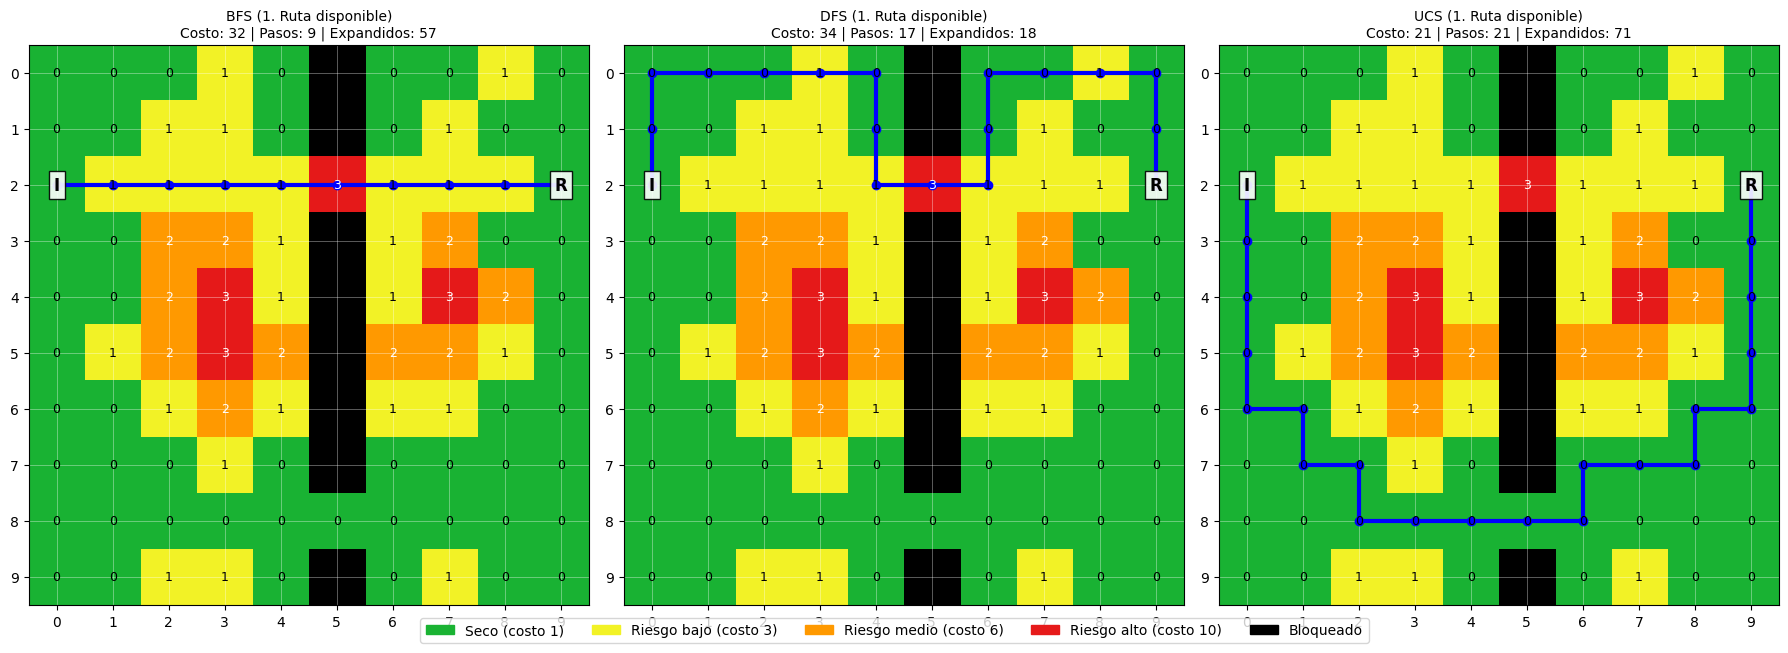

In [9]:
import pandas as pd

# =========================================================================
# 1. LISTA GLOBAL DE TABLAS
# =========================================================================
TABLAS = []

# =========================================================================
# 2. FUNCIÓN DE EJECUCIÓN DE ESCENARIOS
# =========================================================================
def ejecutar_escenario(nombre, mapa, inicio, refugio, mostrar=True):
    """
    Ejecuta BFS, DFS y UCS sobre el mapa provisto, valida las rutas generadas
    y resume las métricas en un DataFrame de Pandas.
    """
    # Ejecución de los algoritmos
    res_bfs = bfs(mapa, inicio, refugio)
    res_dfs = dfs(mapa, inicio, refugio)
    res_ucs = ucs(mapa, inicio, refugio)

    algoritmos = {
        "BFS": res_bfs,
        "DFS": res_dfs,
        "UCS": res_ucs
    }

    filas = []
    resultados = {}

    for nombre_alg, (ruta, costo, nodos) in algoritmos.items():
        # Almacenamos el resultado en el formato solicitado
        resultados[nombre_alg] = (ruta, costo, nodos)

        # Validación independiente
        if ruta is not None:
            es_valida, errores, costo_recalc = validar_ruta(mapa, ruta, inicio, refugio, costo)
            if not es_valida:
                raise AssertionError(
                    f"Error de validación en Escenario: '{nombre}', Algoritmo: '{nombre_alg}'. "
                    f"Errores detectados: {errores}"
                )
            hay_ruta_str = "Sí"
            valida_str = "Sí"
            pasos = len(ruta) - 1
        else:
            hay_ruta_str = "No"
            valida_str = "N/A"
            costo = None
            pasos = None

        # Construcción de la fila de datos para el DataFrame
        filas.append({
            "Escenario": nombre,
            "Algoritmo": nombre_alg,
            "¿Hay ruta?": hay_ruta_str,
            "¿Válida?": valida_str,
            "Costo": costo,
            "Pasos": pasos,
            "Nodos expandidos": nodos
        })

    # Crear el DataFrame con el orden de columnas solicitado
    df = pd.DataFrame(filas, columns=[
        "Escenario", "Algoritmo", "¿Hay ruta?", "¿Válida?", "Costo", "Pasos", "Nodos expandidos"
    ])

    # Agregar a la lista global
    TABLAS.append(df)

    # Mostrar visualizaciones si se solicita
    if mostrar:
        print(f"\n--- DATOS DEL ESCENARIO: {nombre} ---")
        display(df)
        comparar_visual(mapa, inicio, refugio, {
            f"{nombre_alg} ({nombre})": datos for nombre_alg, datos in resultados.items()
        })

    return df, resultados

# =========================================================================
# 3. PRUEBA 1 – Ruta disponible
# =========================================================================
print("Ejecutando Prueba 1...")
mapa1 = crear_mapa_principal()
df1, res1 = ejecutar_escenario("1. Ruta disponible", mapa1, INICIO, REFUGIO)

# Desestructuración de resultados
ruta_bfs1, costo_bfs1, _ = res1["BFS"]
ruta_dfs1, costo_dfs1, _ = res1["DFS"]
ruta_ucs1, costo_ucs1, _ = res1["UCS"]

# Aserciones para la Prueba 1
assert ruta_bfs1 is not None and ruta_dfs1 is not None and ruta_ucs1 is not None, "Las tres rutas deben existir."
assert costo_bfs1 == 32, f"Costo BFS esperado: 32, obtenido: {costo_bfs1}"
assert costo_dfs1 == 34, f"Costo DFS esperado: 34, obtenido: {costo_dfs1}"
assert costo_ucs1 == 21, f

Ejecutando Prueba 2a...

--- DATOS DEL ESCENARIO: 2a. Se bloquea (8,5) ---


,Escenario,Algoritmo,¿Hay ruta?,¿Válida?,Costo,Pasos,Nodos expandidos
0,"2a. Se bloquea (8,5)",BFS,Sí,Sí,32,9,57
1,"2a. Se bloquea (8,5)",DFS,Sí,Sí,34,17,18
2,"2a. Se bloquea (8,5)",UCS,Sí,Sí,32,9,64


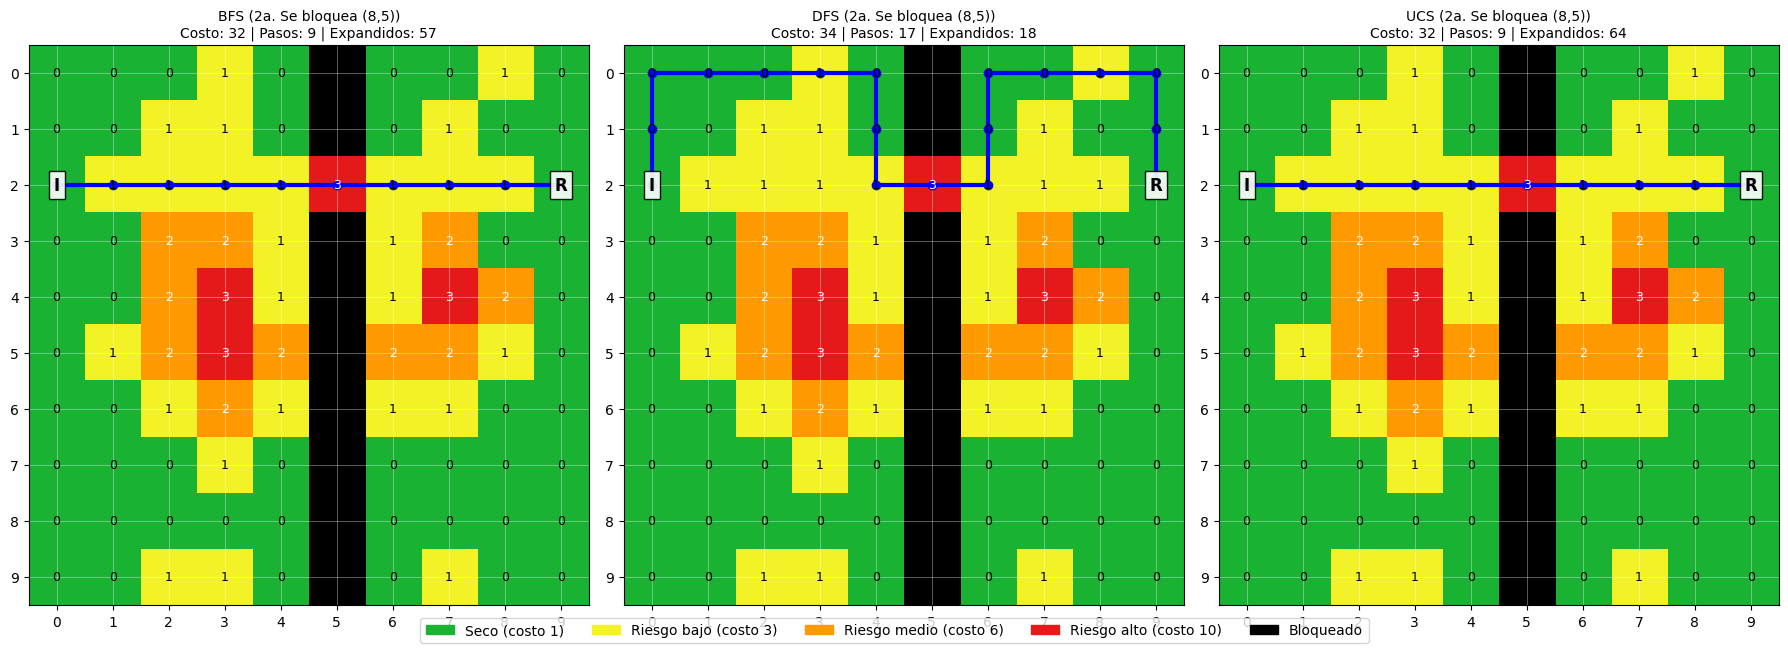


Ejecutando Prueba 2b...

--- DATOS DEL ESCENARIO: 2b. Se bloquea (2,5) ---


,Escenario,Algoritmo,¿Hay ruta?,¿Válida?,Costo,Pasos,Nodos expandidos
0,"2b. Se bloquea (2,5)",BFS,Sí,Sí,57,21,88
1,"2b. Se bloquea (2,5)",DFS,Sí,Sí,59,29,30
2,"2b. Se bloquea (2,5)",UCS,Sí,Sí,21,21,71


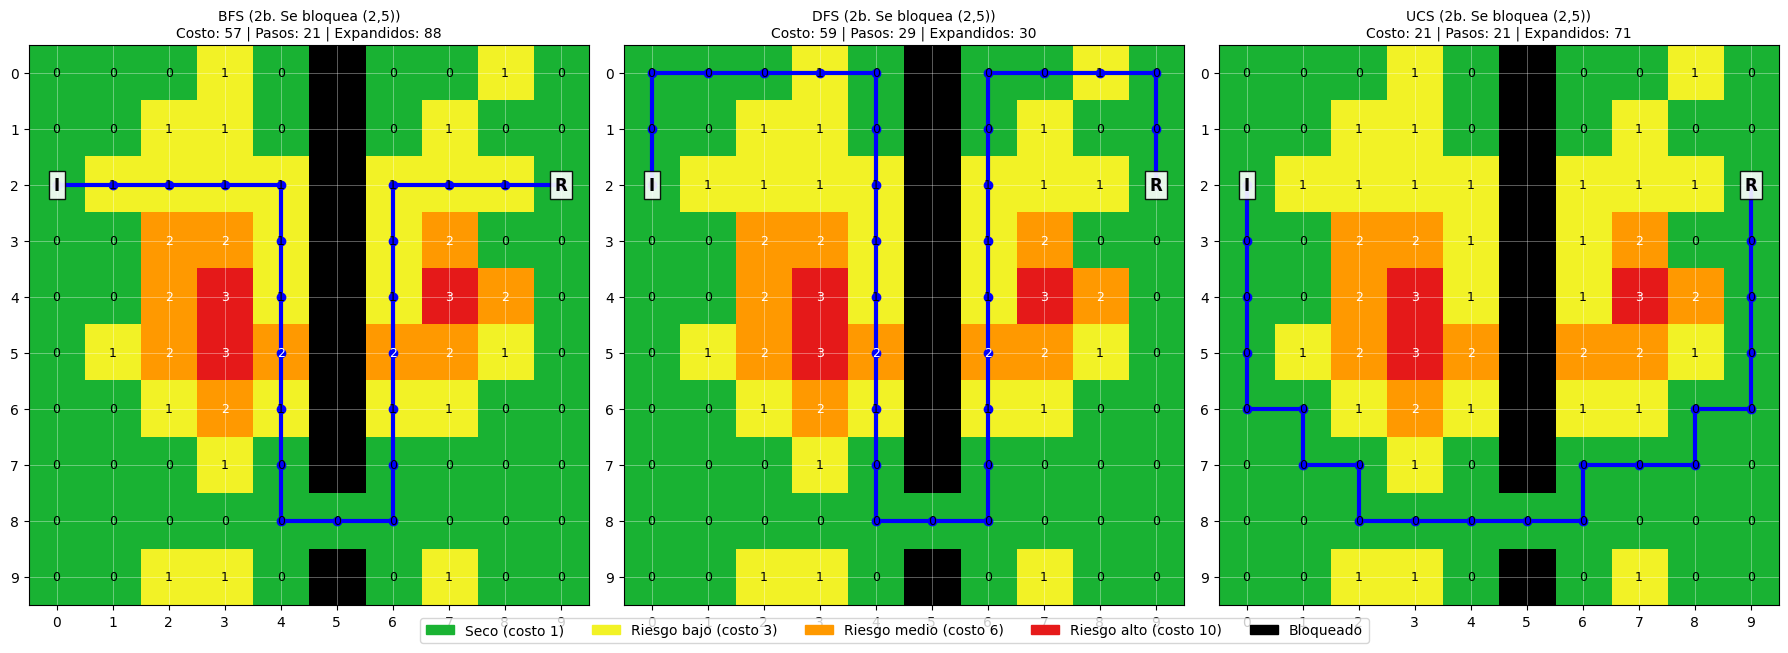


Ejecutando Prueba 3...

--- DATOS DEL ESCENARIO: 3. Refugio inaccesible ---


,Escenario,Algoritmo,¿Hay ruta?,¿Válida?,Costo,Pasos,Nodos expandidos
0,3. Refugio inaccesible,BFS,No,N/A,None,None,88
1,3. Refugio inaccesible,DFS,No,N/A,None,None,88
2,3. Refugio inaccesible,UCS,No,N/A,None,None,88


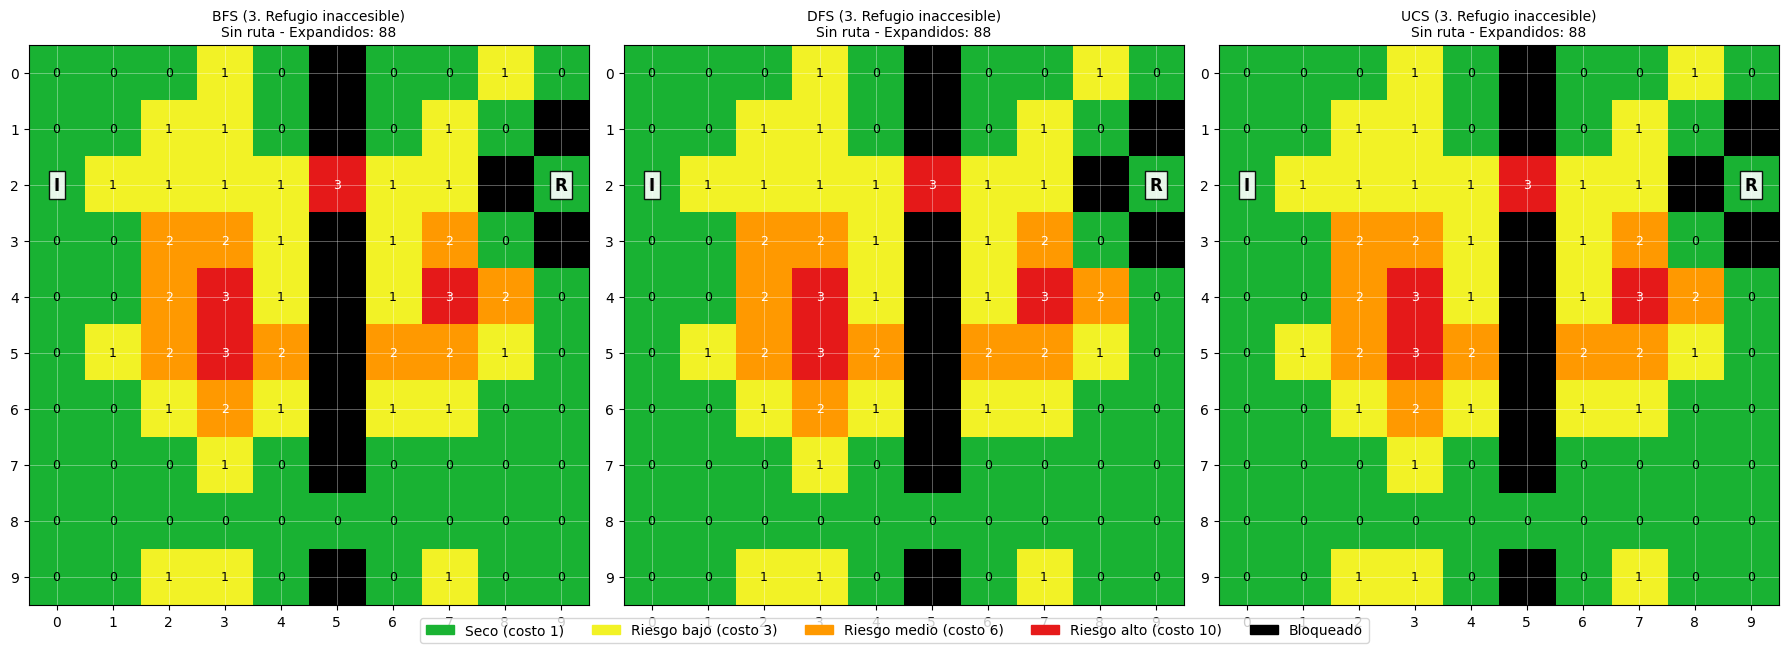


Parte 8: todas las pruebas pasaron


In [11]:
# Recuperamos la ruta original de UCS obtenida en la Prueba 1
ruta_ucs_original = ruta_ucs1

# =========================================================================
# PRUEBA 2a – Se bloquea una celda de la ruta de UCS
# =========================================================================
print("Ejecutando Prueba 2a...")

# Confirmar que la celda (8, 5) estaba en la ruta original de UCS
assert (8, 5) in ruta_ucs_original, "La celda (8, 5) debería estar en la ruta UCS original."

# Crear copia del mapa y bloquear la celda (8, 5)
mapa2a = crear_mapa_principal()
mapa2a[8, 5] = BLOQUEADO

# Ejecutar el escenario
df2a, res2a = ejecutar_escenario("2a. Se bloquea (8,5)", mapa2a, INICIO, REFUGIO)

# Desestructurar resultados de la prueba 2a
ruta_bfs2a, costo_bfs2a, _ = res2a["BFS"]
ruta_dfs2a, costo_dfs2a, _ = res2a["DFS"]
ruta_ucs2a, costo_ucs2a, _ = res2a["UCS"]

# Aserciones para Prueba 2a
assert ruta_ucs2a is not None, "La nueva ruta de UCS debería existir."
assert (8, 5) not in ruta_ucs2a, "La nueva ruta de UCS no debería contener la celda bloqueada (8, 5)."
assert (2, 5) in ruta_ucs2a, "La nueva ruta de UCS debería contener la celda (2, 5) al verse forzada a subir."
assert costo_ucs2a > 21, f"El costo de UCS ({costo_ucs2a}) debería ser estrictamente mayor que 21."
assert costo_bfs2a == 32, f"El costo de BFS debería seguir siendo 32, se obtuvo: {costo_bfs2a}"
assert costo_dfs2a == 34, f"El costo de DFS debería seguir siendo 34, se obtuvo: {costo_dfs2a}"

# =========================================================================
# PRUEBA 2b – Se bloquea una celda de las rutas de BFS y DFS
# =========================================================================
print("\nEjecutando Prueba 2b...")

# Crear copia del mapa y bloquear la celda (2, 5)
mapa2b = crear_mapa_principal()
mapa2b[2, 5] = BLOQUEADO

# Ejecutar el escenario
df2b, res2b = ejecutar_escenario("2b. Se bloquea (2,5)", mapa2b, INICIO, REFUGIO)

# Desestructurar resultados de la prueba 2b
ruta_bfs2b, costo_bfs2b, _ = res2b["BFS"]
ruta_dfs2b, costo_dfs2b, _ = res2b["DFS"]
ruta_ucs2b, costo_ucs2b, _ = res2b["UCS"]

# Aserciones para Prueba 2b
assert ruta_bfs2b is not None and ruta_dfs2b is not None and ruta_ucs2b is not None, "Las rutas de BFS, DFS y UCS deben existir."
assert (2, 5) not in ruta_bfs2b, "La ruta de BFS no debe contener (2, 5)."
assert (2, 5) not in ruta_dfs2b, "La ruta de DFS no debe contener (2, 5)."
assert (2, 5) not in ruta_ucs2b, "La ruta de UCS no debe contener (2, 5)."

pasos_bfs2b = len(ruta_bfs2b) - 1
assert pasos_bfs2b == 21, f"BFS debería tener exactamente 21 pasos, se obtuvieron: {pasos_bfs2b}"
assert costo_ucs2b == 21, f"UCS debería mantener un costo óptimo de 21, se obtuvo: {costo_ucs2b}"

# =========================================================================
# PRUEBA 3 – Refugio inaccesible
# =========================================================================
print("\nEjecutando Prueba 3...")

# Crear copia del mapa y aislar por completo el refugio
mapa3 = crear_mapa_principal()
mapa3[1, 9] = BLOQUEADO
mapa3[3, 9] = BLOQUEADO
mapa3[2, 8] = BLOQUEADO

# Ejecutar escenario sin que lance excepciones
df3, res3 = ejecutar_escenario("3. Refugio inaccesible", mapa3, INICIO, REFUGIO)

# Desestructurar resultados de la prueba 3
ruta_bfs3, costo_bfs3, nodos_bfs3 = res3["BFS"]
ruta_dfs3, costo_dfs3, nodos_dfs3 = res3["DFS"]
ruta_ucs3, costo_ucs3, nodos_ucs3 = res3["UCS"]

# Aserciones para Prueba 3
assert ruta_bfs3 is None and costo_bfs3 is None, "BFS no debería encontrar ruta."
assert ruta_dfs3 is None and costo_dfs3 is None, "DFS no debería encontrar ruta."
assert ruta_ucs3 is None and costo_ucs3 is None, "UCS no debería encontrar ruta."

# Validar alcanzabilidad
recanzable = refugio_es_alcanzable(mapa3, INICIO, REFUGIO)
assert recanzable is False, "El refugio no debería ser alcanzable en mapa3."

# Validar nodos expandidos (deben ser idénticos e iguales a 88 celdas transitables accesibles)
assert nodos_bfs3 == 88, f"Nodos expandidos BFS esperados: 88, obtenidos: {nodos_bfs3}"
assert nodos_dfs3 == 88, f"Nodos expandidos DFS esperados: 88, obtenidos: {nodos_dfs3}"
assert nodos_ucs3 == 88, f"Nodos expandidos UCS esperados: 88, obtenidos: {nodos_ucs3}"

# Validar la ruta nula de forma directa con la función de validación independiente
es_valida_null, _, _ = validar_ruta(mapa3, None, INICIO, REFUGIO)
assert es_valida_null is False, "validar_ruta con None debe retornar False."

# Finalización exitosa
print("\nParte 8: todas las pruebas pasaron")